# 09 · Health-class classification (EOL risk / Degraded / Healthy)

**Owner:** Shraddhaben Patel (Step 5: hand-off to classification)

The regression notebooks predict SOH as a number. This notebook asks a different question: **can SOH be turned into reliable health categories, and does that hold up on cells and profiles the model has never seen?**

**Classes (project definition, unchanged):** `EOL risk` = SOH < 80, `Degraded` = 80 to < 90, `Healthy` = SOH >= 90 (80 % is the usual automotive end-of-life point).

**What this notebook does**
1. Counts the classes on the 306 labelled rows and decides whether classification is feasible.
2. **Approach A, direct classifier:** logistic regression, decision tree and random forest, plus a majority-class floor.
3. **Approach B, regress then threshold:** take the out-of-fold SOH predictions of the regression models and cut them at 80 and 90 (the same view as `08_model_comparison`, section 5).
4. Compares A and B with **macro-F1 and EOL-risk recall** on pooled out-of-fold predictions, on the random, unseen-cell (LOCO, headline) and unseen-profile (LOPO) splits.

**Protocol (nothing is chosen in this notebook):** same 306 rows, same inputs (`ev.main_features()`, no leaky or comparison columns), same fixed folds, and the same fold-safe preprocessing (pruning, clipping, imputation, scaling, one-hot) as every other model (`src/evaluation.py`). Tuning grids are declared in `src/classification.py` before any run. Tuning is nested with an inner grouped CV; the inner objective is balanced accuracy. The locked hold-out cells are not used. No existing file is modified; this notebook only reads the teammates' saved predictions.

In [1]:
from pathlib import Path
import sys, warnings
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.metrics import confusion_matrix, f1_score
from src import evaluation as ev
from src import classification as cl
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)

OUT = cl.OUT_DIR; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
df = ev.load_labelled()
numeric, categorical = ev.main_features()
LABELS = cl.LABELS
SHORT = {"EOL risk (<80)": "EOL risk", "Degraded (80-90)": "Degraded", "Healthy (>=90)": "Healthy"}
COL = {"Direct classifier": "#4C78A8", "Regression, then threshold": "#E8833A"}
print(len(df), "labelled rows |", df.cell_id.nunique(), "cells |", df.profile.nunique(), "profiles |",
      len(numeric), "numeric inputs +", categorical)

306 labelled rows | 15 cells | 14 profiles | 42 numeric inputs + ['schedule']


## 1. Class counts and feasibility check

Classification is only run if every class has enough examples **and** enough independent cells. Rows from the same cell are almost copies of each other, so the number of **cells** matters more than the number of rows.

,rows,share_%,cells_with_class
health_class,,,
EOL risk (<80),53,17.3,8
Degraded (80-90),66,21.6,12
Healthy (>=90),187,61.1,15


cell_id,2_009,2_010,2_012,2_027,2_030,2_033,2_058,2_067,2_076,2_092,2_095,2_098,2_101,2_104,2_108
health_class,,,,,,,,,,,,,,,
EOL risk (<80),0,0,16,0,0,3,2,6,5,0,8,0,5,8,0
Degraded (80-90),4,1,3,0,5,5,7,8,0,2,4,7,12,8,0
Healthy (>=90),17,20,3,22,17,14,13,7,1,20,4,15,5,6,23


LOCO folds whose held-out cell has no EOL-risk rows: 7 of 15 -> ['2_009', '2_010', '2_027', '2_030', '2_092', '2_098', '2_108']


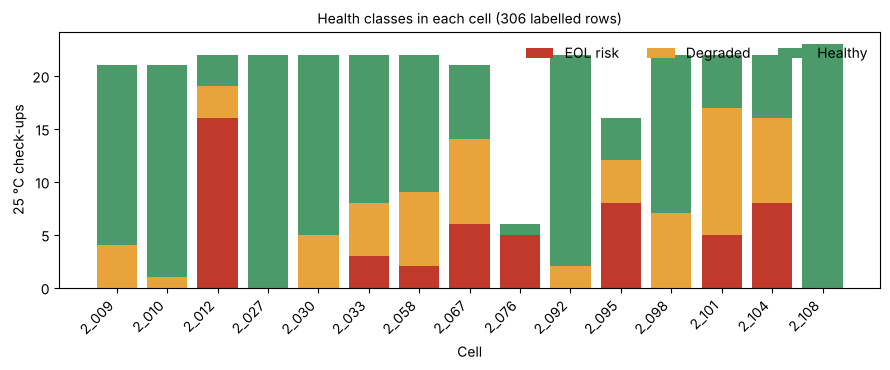

In [2]:
counts = df.health_class.value_counts().reindex(LABELS).rename("rows").to_frame()
counts["share_%"] = (100 * counts.rows / len(df)).round(1)
counts["cells_with_class"] = [df.loc[df.health_class == c, "cell_id"].nunique() for c in LABELS]
display(counts)
per_cell = pd.crosstab(df.cell_id, df.health_class).reindex(columns=LABELS)
display(per_cell.T)
no_eol = per_cell.index[per_cell[LABELS[0]] == 0].tolist()
print("LOCO folds whose held-out cell has no EOL-risk rows:", len(no_eol), "of", df.cell_id.nunique(), "->", no_eol)
counts.to_csv(OUT / "class_counts.csv"); per_cell.to_csv(OUT / "class_counts_by_cell.csv")

fig, ax = plt.subplots(figsize=(9, 3.8))
bottom = np.zeros(len(per_cell)); colors = ["#C0392B", "#E8A33A", "#4C9A6A"]
for lab, c in zip(LABELS, colors):
    ax.bar(per_cell.index, per_cell[lab], bottom=bottom, color=c, label=SHORT[lab]); bottom += per_cell[lab].to_numpy()
ax.set_ylabel("25 °C check-ups"); ax.set_xlabel("Cell"); ax.legend(frameon=False, ncol=3)
ax.set_title("Health classes in each cell (306 labelled rows)", fontsize=10)
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.savefig(FIG / "class_counts_by_cell.png", dpi=200); plt.show()

**Feasibility decision.** On the expanded table all three classes exist (see the table above), far better than the one-cell pilot (1 Healthy against 56 Degraded). The weak spots are real and are carried through the rest of the notebook:
* **EOL risk** comes from only **8 cells**, and several LOCO folds hold out a cell with no EOL rows. For that reason every score below is computed on the **pooled** out-of-fold predictions, never per fold.
* **Degraded** (80 to 90) is a narrow band, so a small SOH error flips a row between neighbouring classes.
* The classes are not equally common (about 61 % Healthy), so accuracy alone is misleading. The headline metrics are **macro-F1** and **EOL-risk recall**; a majority-class model is included as the floor.

Classification is therefore feasible but limited, and it is reported as such.

## 2. Approach A: direct classifiers (nested, fold-safe)
Results are cached in `results/classification/oof_direct.csv`; delete that file to re-run (about 6 to 10 minutes).

In [3]:
cache = OUT / "oof_direct.csv"
if cache.exists():
    direct = pd.read_csv(cache)
else:
    parts = []
    for scheme in ["LOCO", "LOPO", "Random 5-fold"]:
        for name in cl.SPECS:
            print(scheme, "|", name, flush=True)
            parts.append(cl.run_direct(df, name, scheme, numeric, categorical))
    direct = pd.concat(parts, ignore_index=True); direct.to_csv(cache, index=False)
print(direct.groupby(["scheme", "model"]).size().unstack(0))

LOCO | Majority class (floor)


LOCO | Logistic regression


LOCO | Decision tree


LOCO | Random forest


LOPO | Majority class (floor)


LOPO | Logistic regression


... (3 outputs left out)

Random 5-fold | Logistic regression


Random 5-fold | Decision tree


Random 5-fold | Random forest


scheme                  LOCO  LOPO  Random 5-fold
model                                            
Decision tree            306   306            306
Logistic regression      306   306            306
Majority class (floor)   306   306            306
Random forest            306   306            306


## 3. Approach B: regress, then threshold
The out-of-fold SOH predictions come from the teammates' notebooks (same folds, same inputs). Each prediction is cut at 80 and 90.

In [4]:
thr = cl.load_regression_thresholded()
cols = ["cell_id", "profile", "idtest", "model", "scheme", "approach", "fold", "regime", "y_soh", "y_true", "y_pred"]
allp = pd.concat([direct[cols], thr[cols]], ignore_index=True)
assert allp.groupby(["scheme", "model"]).size().eq(len(df)).all(), "every model must predict all 306 rows once per scheme"
M = cl.metric_table(allp); M.to_csv(OUT / "classification_metrics.csv", index=False)
B = cl.binary_table(allp); B.to_csv(OUT / "classification_binary_views.csv", index=False)
allp.to_csv(OUT / "oof_all_classification.csv", index=False)

# Cross-check against Rachandeep's classification view (08_model_comparison, section 5): same predictions, same cut-offs.
rc = ROOT / "results" / "model_comparison" / "loco_classification_view.csv"
if rc.exists():
    r = pd.read_csv(rc).set_index("model")
    mine = M[(M.scheme == "LOCO") & (M.approach == "Regression, then threshold")].set_index("model")
    pairs = {"Ridge": "Ridge", "Lasso": "Lasso", "ElasticNet": "ElasticNet", "SVR (RBF)": "SVR (RBF)",
             "HistGradientBoosting": "Gradient boosting (HGB)", "Random forest (regressor)": "Random forest",
             "Gaussian process": "Gaussian process"}
    chk = pd.DataFrame({"mine macro_F1": {k: mine.loc[k, "macro_F1"] for k in pairs}, "teammate macro_F1": {k: r.loc[v, "macro_F1"] for k, v in pairs.items()},
                        "mine EOL_recall": {k: mine.loc[k, "EOL_recall"] for k in pairs}, "teammate EOL_recall": {k: r.loc[v, "EOL_recall"] for k, v in pairs.items()}})
    display(chk.round(4)); print("max abs difference:", float((chk.iloc[:, [0, 2]].to_numpy() - chk.iloc[:, [1, 3]].to_numpy()).__abs__().max()))
else:
    print("results/model_comparison/loco_classification_view.csv not found; skipping the cross-check")

show = ["approach", "model", "accuracy", "balanced_accuracy", "macro_F1", "EOL_precision", "EOL_recall", "EOL_F1", "Degraded_recall", "Healthy_recall"]
loco = M[M.scheme == "LOCO"].sort_values("macro_F1", ascending=False)[show].round(3).reset_index(drop=True)
display(loco)

,mine macro_F1,teammate macro_F1,mine EOL_recall,teammate EOL_recall
Ridge,0.7324,0.7324,0.7547,0.7547
Lasso,0.7264,0.7264,0.6981,0.6981
ElasticNet,0.7215,0.7215,0.7170,0.7170
SVR (RBF),0.6588,0.6588,0.4906,0.4906
HistGradientBoosting,0.6852,0.6852,0.6038,0.6038
Random forest (regressor),0.6779,0.6779,0.5283,0.5283
Gaussian process,0.5031,0.5031,0.2830,0.2830


max abs difference: 4.6311674975041406e-05


,approach,model,accuracy,balanced_accuracy,macro_F1,EOL_precision,EOL_recall,EOL_F1,Degraded_recall,Healthy_recall
0,"Regression, then threshold",Ridge,0.755,0.775,0.732,0.727,0.755,0.741,0.848,0.722
1,"Regression, then threshold",Lasso,0.755,0.765,0.726,0.712,0.698,0.705,0.864,0.733
2,"Regression, then threshold",ElasticNet,0.739,0.760,0.721,0.776,0.717,0.745,0.864,0.701
3,Direct classifier,Logistic regression,0.781,0.691,0.706,0.853,0.547,0.667,0.621,0.904
4,"Regression, then threshold",HistGradientBoosting,0.732,0.697,0.685,0.744,0.604,0.667,0.712,0.775
5,"Regression, then threshold",Random forest (regressor),0.742,0.694,0.678,0.651,0.528,0.583,0.758,0.797
6,Direct classifier,Random forest,0.755,0.675,0.677,0.714,0.472,0.568,0.697,0.856
7,Direct classifier,Decision tree,0.758,0.673,0.676,0.786,0.415,0.543,0.742,0.861
8,"Regression, then threshold",SVR (RBF),0.716,0.674,0.659,0.722,0.491,0.584,0.773,0.759
9,"Regression, then threshold",Gaussian process,0.611,0.512,0.503,0.312,0.283,0.297,0.515,0.738


## 4. Results

### 4.1 Unseen cells (LOCO, headline)
Pooled out-of-fold metrics, 306 rows, 15 folds.

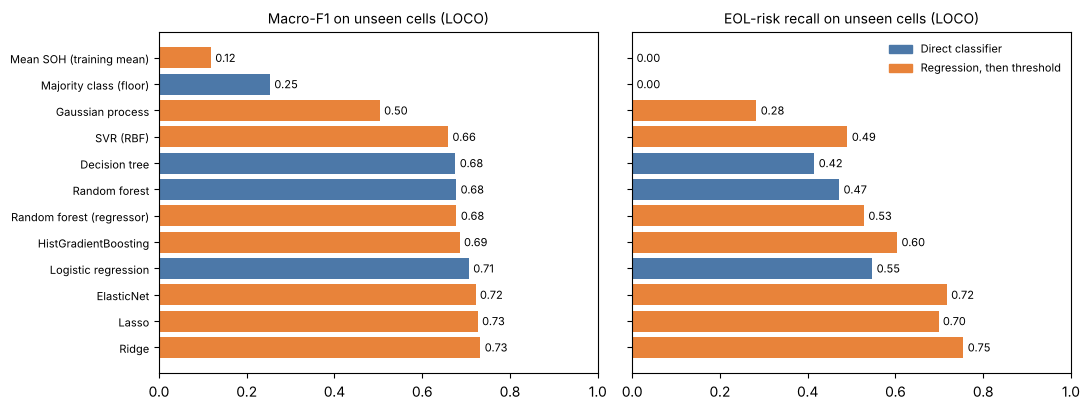

In [5]:
order = loco.model.tolist()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, metric, title in zip(axes, ["macro_F1", "EOL_recall"], ["Macro-F1", "EOL-risk recall"]):
    sub = M[M.scheme == "LOCO"].set_index("model").loc[order]
    ax.barh(range(len(order)), sub[metric], color=[COL[a] for a in sub.approach])
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, fontsize=8); ax.invert_yaxis()
    for i, v in enumerate(sub[metric]): ax.text(v + 0.01, i, f"{v:.2f}", va="center", fontsize=8)
    ax.set_xlim(0, 1); ax.set_title(title + " on unseen cells (LOCO)", fontsize=10)
from matplotlib.patches import Patch
axes[1].legend(handles=[Patch(color=c, label=a) for a, c in COL.items()], frameon=False, fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "loco_macroF1_eolrecall.png", dpi=200); plt.show()

### 4.2 Random split versus unseen cells versus unseen profiles
Random splits put check-ups of the same cell in training and test, so they look better than they should. The gap is the cost of testing on a new cell or profile.

scheme                                                Random 5-fold   LOCO   LOPO  gap: random - LOCO
approach                   model                                                                     
Regression, then threshold Ridge                              0.831  0.732  0.645               0.099
                           Lasso                              0.826  0.726  0.692               0.100
                           ElasticNet                         0.835  0.721  0.722               0.114
Direct classifier          Logistic regression                0.866  0.706  0.658               0.159
Regression, then threshold HistGradientBoosting               0.899  0.685  0.714               0.214
                           Random forest (regressor)          0.879  0.678  0.703               0.201
Direct classifier          Random forest                      0.873  0.677  0.650               0.196
                           Decision tree                      0.810  0.676  0.679               0.134
Regression, then threshold SVR (RBF)                          0.926  0.659  0.554               0.267
                           Gaussian process                   0.927  0.503  0.486               0.424
Direct classifier          Majority class (floor)             0.253  0.253  0.253               0.000
Regression, then threshold Mean SOH (training mean)           0.118  0.118  0.118               0.000

EOL-risk recall


scheme                                                Random 5-fold   LOCO   LOPO
approach                   model                                                 
Regression, then threshold Ridge                              0.830  0.755  0.491
                           Lasso                              0.830  0.698  0.623
                           ElasticNet                         0.830  0.717  0.642
Direct classifier          Logistic regression                0.943  0.547  0.547
Regression, then threshold HistGradientBoosting               0.925  0.604  0.528
                           Random forest (regressor)          0.887  0.528  0.547
Direct classifier          Random forest                      0.925  0.472  0.472
                           Decision tree                      0.849  0.415  0.415
Regression, then threshold SVR (RBF)                          0.962  0.491  0.321
                           Gaussian process                   0.925  0.283  0.283
Direct classifier          Majority class (floor)             0.000  0.000  0.000
Regression, then threshold Mean SOH (training mean)           0.000  0.000  0.000

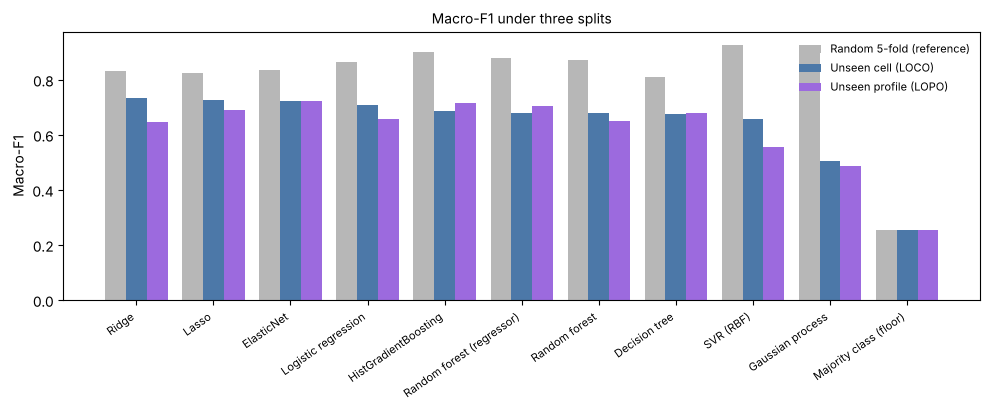

In [6]:
wide = M.pivot_table(index=["approach", "model"], columns="scheme", values="macro_F1")[["Random 5-fold", "LOCO", "LOPO"]]
wide["gap: random - LOCO"] = wide["Random 5-fold"] - wide["LOCO"]
wide = wide.sort_values("LOCO", ascending=False).round(3); display(wide)
wide_eol = M.pivot_table(index=["approach", "model"], columns="scheme", values="EOL_recall")[["Random 5-fold", "LOCO", "LOPO"]].round(3)
print("EOL-risk recall"); display(wide_eol.loc[wide.index])
wide.to_csv(OUT / "macroF1_by_scheme.csv"); wide_eol.to_csv(OUT / "EOLrecall_by_scheme.csv")

keep = [m for m in order if m not in ("Mean SOH (training mean)",)]
fig, ax = plt.subplots(figsize=(10, 4.2)); w = 0.27
for j, (sch, c) in enumerate(zip(["Random 5-fold", "LOCO", "LOPO"], ["#B7B7B7", "#4C78A8", "#9C6ADE"])):
    vals = [M[(M.scheme == sch) & (M.model == m)].macro_F1.iloc[0] for m in keep]
    ax.bar(np.arange(len(keep)) + (j - 1) * w, vals, w, color=c, label={"LOCO": "Unseen cell (LOCO)", "LOPO": "Unseen profile (LOPO)"}.get(sch, "Random 5-fold (reference)"))
ax.set_xticks(range(len(keep))); ax.set_xticklabels(keep, rotation=35, ha="right", fontsize=8); ax.set_ylabel("Macro-F1")
ax.legend(frameon=False, fontsize=8); ax.set_title("Macro-F1 under three splits", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "macroF1_three_splits.png", dpi=200); plt.show()

### 4.3 Two-class views at 80 and 90
The same predictions collapsed into 'below the cut-off' against 'at or above'. The cut at 80 is the end-of-life question; the cut at 90 asks whether a cell has started to age at all.

In [7]:
b = B[B.scheme == "LOCO"].copy()
for cut in (80, 90):
    t = b[b.cut == cut].sort_values("F1", ascending=False)[["approach", "model", "positives", "recall", "precision", "specificity", "F1", "balanced_accuracy"]].round(3)
    print(f"LOCO, positive = SOH below {cut}"); display(t.reset_index(drop=True))

LOCO, positive = SOH below 80


,approach,model,positives,recall,precision,specificity,F1,balanced_accuracy
0,"Regression, then threshold",ElasticNet,53,0.717,0.776,0.957,0.745,0.837
1,"Regression, then threshold",Ridge,53,0.755,0.727,0.941,0.741,0.848
2,"Regression, then threshold",Lasso,53,0.698,0.712,0.941,0.705,0.819
3,Direct classifier,Logistic regression,53,0.547,0.853,0.980,0.667,0.764
4,"Regression, then threshold",HistGradientBoosting,53,0.604,0.744,0.957,0.667,0.780
5,"Regression, then threshold",SVR (RBF),53,0.491,0.722,0.960,0.584,0.726
6,"Regression, then threshold",Random forest (regressor),53,0.528,0.651,0.941,0.583,0.735
7,Direct classifier,Random forest,53,0.472,0.714,0.960,0.568,0.716
8,Direct classifier,Decision tree,53,0.415,0.786,0.976,0.543,0.696
9,"Regression, then threshold",Gaussian process,53,0.283,0.312,0.870,0.297,0.576


LOCO, positive = SOH below 90


,approach,model,positives,recall,precision,specificity,F1,balanced_accuracy
0,Direct classifier,Logistic regression,119,0.815,0.843,0.904,0.829,0.859
1,"Regression, then threshold",Random forest (regressor),119,0.908,0.740,0.797,0.815,0.852
2,"Regression, then threshold",Ridge,119,0.975,0.690,0.722,0.808,0.848
3,"Regression, then threshold",HistGradientBoosting,119,0.908,0.720,0.775,0.803,0.841
4,"Regression, then threshold",Lasso,119,0.950,0.693,0.733,0.801,0.841
5,"Regression, then threshold",SVR (RBF),119,0.916,0.708,0.759,0.799,0.838
6,"Regression, then threshold",ElasticNet,119,0.975,0.674,0.701,0.797,0.838
7,Direct classifier,Random forest,119,0.798,0.779,0.856,0.788,0.827
8,Direct classifier,Decision tree,119,0.790,0.783,0.861,0.787,0.825
9,"Regression, then threshold",Gaussian process,119,0.765,0.650,0.738,0.703,0.751


### 4.4 Confusion matrices (LOCO)
Rows are the true class, columns the predicted class. Pooled over all 15 held-out cells.

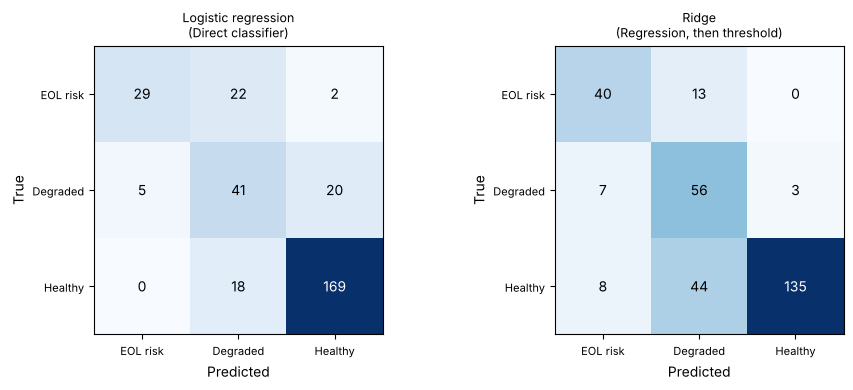

picked: [('Direct classifier', 'Logistic regression'), ('Regression, then threshold', 'Ridge')]


In [8]:
def best(approach):
    t = M[(M.scheme == "LOCO") & (M.approach == approach) & (M.model != "Majority class (floor)") & (M.model != "Mean SOH (training mean)")]
    return t.sort_values("macro_F1", ascending=False).model.iloc[0]
picks = [("Direct classifier", best("Direct classifier")), ("Regression, then threshold", best("Regression, then threshold"))]
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, (app, mname) in zip(axes, picks):
    g = allp[(allp.scheme == "LOCO") & (allp.model == mname)]
    cm = confusion_matrix(g.y_true, g.y_pred, labels=LABELS)
    ax.imshow(cm, cmap="Blues")
    for i in range(3):
        for j in range(3):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(3)); ax.set_xticklabels([SHORT[l] for l in LABELS], fontsize=8); ax.set_yticks(range(3)); ax.set_yticklabels([SHORT[l] for l in LABELS], fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{mname}\n({app})", fontsize=9)
    pd.DataFrame(cm, index=[SHORT[l] for l in LABELS], columns=[SHORT[l] for l in LABELS]).to_csv(OUT / f"confusion_LOCO_{mname.replace(' ', '_').replace('(', '').replace(')', '')}.csv")
plt.tight_layout(); plt.savefig(FIG / "confusion_matrices_LOCO.png", dpi=200); plt.show()
print("picked:", picks)

### 4.5 Where do the mistakes happen?

In [9]:
rank = {l: i for i, l in enumerate(LABELS)}
rows = []
for m in [p[1] for p in picks]:
    g = allp[(allp.scheme == "LOCO") & (allp.model == m)]
    step = (g.y_true.map(rank) - g.y_pred.map(rank)).abs()
    err = g[step > 0]
    rows.append(dict(model=m, errors=len(err), one_class_off=int((step == 1).sum()), EOL_vs_Healthy_confusions=int((step == 2).sum()),
                     share_one_class_off=round((step == 1).sum() / max(len(err), 1), 3)))
display(pd.DataFrame(rows))

print("Accuracy by regime (does the held-out profile lie inside the training range?)")
reg = allp[(allp.scheme == "LOCO") & allp.model.isin([p[1] for p in picks])].assign(ok=lambda d: d.y_true == d.y_pred)
display(reg.groupby(["model", "regime"]).ok.agg(rows="size", accuracy="mean").round(3).reset_index())

pc = (allp[(allp.scheme == "LOCO") & allp.model.isin([p[1] for p in picks])].assign(ok=lambda d: d.y_true == d.y_pred)
      .pivot_table(index="cell_id", columns="model", values="ok", aggfunc="mean").round(2))
pc["EOL rows"] = per_cell[LABELS[0]]; display(pc)
pc.to_csv(OUT / "per_cell_accuracy_LOCO.csv")

,model,errors,one_class_off,EOL_vs_Healthy_confusions,share_one_class_off
0,Logistic regression,67,65,2,0.970
1,Ridge,75,67,8,0.893


Accuracy by regime (does the held-out profile lie inside the training range?)


,model,regime,rows,accuracy
0,Logistic regression,extrapolation,66,0.652
1,Logistic regression,interpolation,219,0.849
2,Logistic regression,unclassified,21,0.476
3,Ridge,extrapolation,66,0.636
4,Ridge,interpolation,219,0.781
5,Ridge,unclassified,21,0.857


model,Logistic regression,Ridge,EOL rows
cell_id,,,
2_009,0.81,0.95,0
2_010,0.76,0.71,0
2_012,0.68,0.91,16
2_027,1.00,1.00,0
2_030,0.91,0.55,0
2_033,0.77,0.41,3
2_058,0.73,0.86,2
2_067,0.48,0.86,6
2_076,0.67,0.83,5


### 4.6 Is the difference between the two approaches real? (paired test and cell-level bootstrap)
With only 15 cells, a better pooled score can be luck. Two checks: a Wilcoxon signed-rank test on per-cell accuracy, and a bootstrap that resamples whole cells.

In [10]:
def per_cell_acc(m):
    g = allp[(allp.scheme == "LOCO") & (allp.model == m)]
    return (g.y_true == g.y_pred).groupby(g.cell_id).mean()
a, b_ = per_cell_acc(picks[0][1]), per_cell_acc(picks[1][1])
try:
    stat, p = wilcoxon(b_.values, a.values, zero_method="wilcox")
except ValueError:
    stat, p = np.nan, np.nan
print(f"per-cell accuracy, {picks[1][1]} (threshold) vs {picks[0][1]} (direct): wins {(b_ > a).sum()}, ties {(b_ == a).sum()}, losses {(b_ < a).sum()} of 15 cells, Wilcoxon p = {p:.3f}")

rng = np.random.default_rng(42); cells = df.cell_id.unique()
def boot(m, n=1000):
    g = allp[(allp.scheme == "LOCO") & (allp.model == m)]; groups = {c: d for c, d in g.groupby("cell_id")}
    mf, er = [], []
    for _ in range(n):
        s = pd.concat([groups[c] for c in rng.choice(cells, len(cells))])
        mf.append(f1_score(s.y_true, s.y_pred, labels=LABELS, average="macro", zero_division=0))
        pos = s.y_true == LABELS[0]; er.append(((s.y_pred == LABELS[0]) & pos).sum() / pos.sum() if pos.sum() else np.nan)
    return np.nanpercentile(mf, [2.5, 97.5]), np.nanpercentile(er, [2.5, 97.5])
ci = []
for app, m in picks + [("Direct classifier", "Majority class (floor)")]:
    f, e = boot(m); ci.append(dict(model=m, macro_F1=round(M[(M.scheme == "LOCO") & (M.model == m)].macro_F1.iloc[0], 3), macro_F1_95CI=f"{f[0]:.2f} to {f[1]:.2f}",
                                   EOL_recall=round(M[(M.scheme == "LOCO") & (M.model == m)].EOL_recall.iloc[0], 3), EOL_recall_95CI=f"{e[0]:.2f} to {e[1]:.2f}"))
ci = pd.DataFrame(ci); display(ci); ci.to_csv(OUT / "bootstrap_ci_LOCO.csv", index=False)

per-cell accuracy, Ridge (threshold) vs Logistic regression (direct): wins 7, ties 3, losses 5 of 15 cells, Wilcoxon p = 0.906


,model,macro_F1,macro_F1_95CI,EOL_recall,EOL_recall_95CI
0,Logistic regression,0.706,0.58 to 0.80,0.547,0.28 to 0.81
1,Ridge,0.732,0.58 to 0.84,0.755,0.50 to 0.93
2,Majority class (floor),0.253,0.21 to 0.29,0.000,0.00 to 0.00


## 5. Feature interpretation (interpretation only, not a score)
These models are fitted **once on all 306 rows** with the shared preprocessing, only to see which inputs drive the class, the same way the baseline notebook shows coefficients from a full fit. They are **not** evaluated on the same rows, so they say nothing about performance. Importance in a model trained on 15 cells describes these cells, not batteries in general.

features kept after redundancy pruning: 25


,RF importance (Gini)
R_1p35C_inst_mean,0.284
R_0p18C_10s_mean,0.209
prev_lp_I_dis_peak,0.112
prev_lp_I_chg_mean,0.073
prev_lp_V_min,0.062
prev_lp_rest_frac,0.035
cum_chg_Ah,0.030
cum_lp_Tdays,0.024
lp_SoC,0.021
cum_lp_days,0.020


,Logistic coef toward EOL risk (standardised)
R_1p35C_inst_mean,2.522
R_0p18C_10s_mean,1.948
lp_SoC,1.542
prev_lp_I_dis_peak,-1.236
lp_CC,1.109
days_since_start,0.922
prev_lp_V_min,-0.786
lp_F,0.543
cum_chg_Ah,0.524
prev_lp_rest_frac,0.518


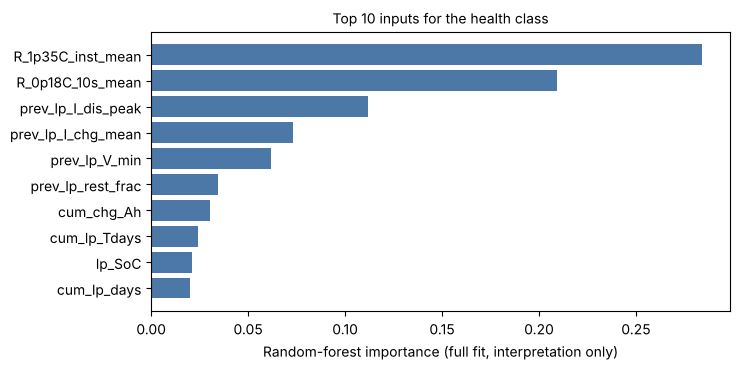

In [11]:
from sklearn.ensemble import RandomForestClassifier
X = df[list(numeric) + list(categorical) + ["cell_id"]]; y = df[ev.TARGET].to_numpy(float)
rf = cl.SOHClassifier(prep=ev.make_preprocessor(numeric, categorical),
                      clf=RandomForestClassifier(n_estimators=300, max_depth=5, min_samples_leaf=3, class_weight="balanced_subsample", random_state=42)).fit(X, y)
names = rf.prep_.get_feature_names_out()
imp = pd.Series(rf.clf_.feature_importances_, index=names).sort_values(ascending=False)
lr = cl.SOHClassifier(prep=ev.make_preprocessor(numeric, categorical),
                      clf=cl.LogisticRegression(class_weight="balanced", max_iter=5000, C=1.0)).fit(X, y)
coef = pd.DataFrame(lr.clf_.coef_, index=lr.clf_.classes_, columns=lr.prep_.get_feature_names_out()).T
print("features kept after redundancy pruning:", len(names))
top = imp.head(10); display(top.round(3).to_frame("RF importance (Gini)"))
eol_coef = coef[LABELS[0]].reindex(coef[LABELS[0]].abs().sort_values(ascending=False).index).head(10)
display(eol_coef.round(3).to_frame("Logistic coef toward EOL risk (standardised)"))
imp.to_csv(OUT / "rf_feature_importance_full_fit.csv"); coef.to_csv(OUT / "logistic_coefficients_full_fit.csv")

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(top.index[::-1], top.values[::-1], color="#4C78A8"); ax.set_xlabel("Random-forest importance (full fit, interpretation only)")
ax.set_title("Top 10 inputs for the health class", fontsize=10); plt.tight_layout(); plt.savefig(FIG / "rf_feature_importance.png", dpi=200); plt.show()

## 6. Summary for the report
**What the numbers show** (pooled out-of-fold predictions, 306 rows, 15 cells; every number is in the tables above and in `results/classification/`)

1. **Classification is feasible, with limits.** All three classes exist (53 EOL risk, 66 Degraded, 187 Healthy). EOL risk comes from only 8 cells, and 7 of the 15 LOCO folds hold out a cell with no EOL rows, so scores are pooled and the confidence intervals are wide.
2. **Every sensible model beats the floor.** The majority-class model reaches macro-F1 0.25 on unseen cells; the best models reach about 0.71 to 0.73. The Gaussian process (0.50) is the exception.
3. **Direct classifiers and thresholded regression are statistically tied on unseen cells.** Ridge-then-threshold has macro-F1 0.73 and EOL recall 0.76; logistic regression has 0.71 and 0.55. The cell-level bootstrap intervals overlap heavily and the paired per-cell test gives p = 0.91, so the data do not show that either approach is better. The direct models have the higher accuracy (logistic regression 0.78) and more precise EOL alarms (0.85 against 0.73) but miss more EOL-risk rows; the thresholded linear models catch more of them. At the 90 cut-off the direct logistic regression is marginally ahead (balanced accuracy 0.86 against 0.85).
4. **Random splits are optimistic.** Macro-F1 drops by about 0.10 to 0.42 from the random split to unseen cells. The flexible models (SVR, Gaussian process, boosted trees) lose the most, as in the regression results. On unseen profiles, EOL recall for thresholded Ridge falls from 0.76 to 0.49.
5. **Most mistakes are one class off.** 97 % of logistic-regression errors and 89 % of Ridge errors are neighbouring classes (for example Degraded predicted as Healthy), because 80 and 90 sit where small SOH errors flip the class. EOL-versus-Healthy confusions are rare for logistic regression (2) and more common for thresholded Ridge (8).
6. **Cells outside the training conditions are harder.** Accuracy is about 0.64 to 0.65 on extrapolation cells against 0.78 to 0.85 on interpolation cells.
7. **Inputs behind the class** (full-fit interpretation only, not scores): pulse resistance (`R_1p35C_inst_mean`, `R_0p18C_10s_mean`) leads in both the random forest and the logistic regression, followed by the previous ageing period's peak discharge current. They describe these 15 cells, not batteries in general.
8. **Consistency with the team.** The thresholded numbers match `08_model_comparison` (section 5) to four decimals (cross-check in section 3), so the report holds one set of numbers.

**Limits to state in the report:** 15 cells; EOL risk from 8 cells; narrow Degraded band; most profiles have a single cell, so unseen-cell and unseen-profile testing nearly coincide; the regression predictions were tuned for MAE and the direct classifiers for balanced accuracy, so the comparison is between two reasonable pipelines, not a perfectly matched pair; the locked hold-out cells were not used.

In [12]:
fact = M[M.scheme.isin(["LOCO", "LOPO", "Random 5-fold"])].round(4)
fact.to_csv(OUT / "fact_sheet_classification.csv", index=False)
print("saved to", OUT)

saved to /tmp/claude-0/-home-claude/fa33ecbd-38a6-532d-88fd-6360de3f0b94/scratchpad/step5/repo/results/classification
